In [1]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [2]:
from pathlib import Path
import numpy as np
import json


def load_poetry_text(folder):

    text_data = ""

    for file in Path(folder).rglob("*.txt"):

        try:
            content = file.read_text(
                encoding="utf-8",
                errors="ignore"
            )

            text_data += content + "\n"

        except Exception as e:
            print(f"Error reading {file}: {e}")

    return text_data


def build_character_vocab(text):

    chars = sorted(list(set(text)))

    stoi = {ch:i for i, ch in enumerate(chars)}
    itos = {i:ch for ch, i in stoi.items()}

    return chars, stoi, itos


def encode(text, stoi):

    return [stoi[c] for c in text]


def decode(tokens, itos):

    return "".join([itos[t] for t in tokens])


def split_dataset(data, ratio=0.9):

    cutoff = int(len(data) * ratio)

    return data[:cutoff], data[cutoff:]


def save_binary(data, filename):

    arr = np.array(data, dtype=np.uint16)

    arr.tofile(filename)


def main():

    print("Loading text corpus...")

    corpus = load_poetry_text(
    "/kaggle/input/datasets/sharanyabhatia/data-task3"
    )

    print(f"Corpus length: {len(corpus):,} characters")

    chars, stoi, itos = build_character_vocab(corpus)

    vocab_size = len(chars)

    print(f"Character Vocabulary Size: {vocab_size}")

    print("Building character mappings...")

    with open("char_stoi.json", "w", encoding="utf-8") as f:
        json.dump(stoi, f, ensure_ascii=False, indent=4)

    with open("char_itos.json", "w", encoding="utf-8") as f:
        json.dump(itos, f, ensure_ascii=False, indent=4)

    print("Encoding corpus...")

    encoded_data = encode(corpus, stoi)

    train_ids, val_ids = split_dataset(encoded_data)

    save_binary(train_ids, "char_train.bin")
    save_binary(val_ids, "char_val.bin")

    print(f"Train tokens: {len(train_ids):,}")
    print(f"Validation tokens: {len(val_ids):,}")

    sample = decode(encoded_data[:200], itos)

    print("\nDecoded Sample:\n")
    print(sample)

    print("\nSample Encoded Tokens:")
    print(encoded_data[:50])

    print("\nDecoded Back:")
    print(decode(encoded_data[:50], itos))


if __name__ == "__main__":
    main()



Loading text corpus...
Corpus length: 21,229,175 characters
Character Vocabulary Size: 1747
Building character mappings...
Encoding corpus...
Train tokens: 19,106,257
Validation tokens: 2,122,918

Decoded Sample:

2 ABC of H.k. and China revised vision.
Barrels tears are wines and salts.
With a whisk on goody tails!
Wiggle maces to fix the heads.
Heads in jack on boxes are ceased.
Cry to paranoid truly bosses.


Sample Encoded Tokens:
[21, 3, 36, 37, 38, 3, 82, 73, 3, 43, 17, 78, 17, 3, 68, 81, 71, 3, 38, 75, 76, 81, 68, 3, 85, 72, 89, 76, 86, 72, 71, 3, 89, 76, 86, 76, 82, 81, 17, 2, 37, 68, 85, 85, 72, 79, 86, 3, 87, 72]

Decoded Back:
2 ABC of H.k. and China revised vision.
Barrels te


In [3]:
import os
import json
from pathlib import Path

import numpy as np
import tiktoken


TOKENIZER = tiktoken.get_encoding("gpt2")
EOT = TOKENIZER.encode(
    "<|endoftext|>",
    allowed_special={"<|endoftext|>"}
)[0]


def collect_text_files(folder):
    return list(Path(folder).rglob("*.txt"))


def tokenize_poetry(source_folder):

    print("\nTokenizing poetry corpus...")

    poem_paths = collect_text_files(source_folder)

    print(f"Discovered {len(poem_paths)} poem files.")

    token_buffer = []

    for poem_path in poem_paths:

        try:
            raw_text = poem_path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).strip()

            if len(raw_text) == 0:
                continue

            encoded = TOKENIZER.encode(
                raw_text,
                allowed_special={"<|endoftext|>"}
            )

            token_buffer.extend(encoded)
            token_buffer.append(EOT)

        except Exception as err:
            print(f"Failed processing {poem_path}: {err}")

    return token_buffer


def build_condition_header(meta):

    genre = meta.get("genre", "unknown")
    mood = meta.get("mood", "unknown")
    rhyme = meta.get("rhyme_scheme", "unknown")
    cadence = meta.get("cadence", "unknown")

    return (
        f"[Genre: {genre}] "
        f"[Mood: {mood}] "
        f"[Rhyme: {rhyme}] "
        f"[Cadence: {cadence}]\n"
    )


def tokenize_rap_dataset(json_path):

    print("\nTokenizing conditioned rap dataset...")

    dataset_tokens = []

    if not os.path.exists(json_path):
        print("Rap dataset not found.")
        return dataset_tokens

    with open(json_path, "r", encoding="utf-8") as handle:
        songs = json.load(handle)

    print(f"Loaded {len(songs)} rap entries.")

    for item in songs:

        metadata = item.get("annotations", {})
        lyrics = item.get("lyrics", "").strip()

        if not lyrics:
            continue

        prefix = build_condition_header(metadata)

        combined_text = prefix + lyrics

        encoded = TOKENIZER.encode(
            combined_text,
            allowed_special={"<|endoftext|>"}
        )

        dataset_tokens.extend(encoded)
        dataset_tokens.append(EOT)

    return dataset_tokens


def split_data(sequence, split_ratio=0.9):

    cutoff = int(len(sequence) * split_ratio)

    return sequence[:cutoff], sequence[cutoff:]


def export_binary(token_sequence, output_name):

    array_data = np.asarray(token_sequence, dtype=np.uint16)

    array_data.tofile(output_name)

    return array_data


def process_and_save(tokens, train_file, val_file, label):

    train_tokens, val_tokens = split_data(tokens)

    train_arr = export_binary(train_tokens, train_file)
    val_arr = export_binary(val_tokens, val_file)

    print(
        f"{label} -> "
        f"train: {len(train_arr):,} | "
        f"val: {len(val_arr):,}"
    )

    if len(train_arr) > 0:
        print(
            f"{label} -> "
            f"unique tokens: {len(np.unique(train_arr)):,} | "
            f"max token id: {np.max(train_arr)}"
        )


def main():

    print(f"GPT2 Vocabulary Size: {TOKENIZER.n_vocab}")

    poem_tokens = tokenize_poetry(
    "/kaggle/input/datasets/sharanyabhatia/data-task3"
    )

    process_and_save(
        poem_tokens,
        "poems_train.bin",
        "poems_val.bin",
        "Poems"
    )
    print("\nSample GPT2 Tokens:")
    print(poem_tokens[:50])
    
    decoded = TOKENIZER.decode(poem_tokens[:50])
    
    print("\nDecoded Sample:")
    print(decoded)

    rap_tokens = tokenize_rap_dataset(
    "/kaggle/input/datasets/sharanyabhatia/data-task3/cleaned_combined.json"
    )

    process_and_save(
        rap_tokens,
        "raps_train.bin",
        "raps_val.bin",
        "Raps"
    )


if __name__ == "__main__":
    main()

GPT2 Vocabulary Size: 50257

Tokenizing poetry corpus...
Discovered 1 poem files.
Poems -> train: 5,503,416 | val: 611,491
Poems -> unique tokens: 39,577 | max token id: 50256

Sample GPT2 Tokens:
[17, 9738, 286, 367, 13, 74, 13, 290, 2807, 15556, 5761, 13, 198, 10374, 2411, 82, 10953, 389, 30680, 290, 37056, 13, 198, 3152, 257, 21060, 319, 922, 88, 30514, 0, 198, 54, 24082, 285, 2114, 284, 4259, 262, 6665, 13, 198, 13847, 82, 287, 14509, 319, 10559, 389, 24368]

Decoded Sample:
2 ABC of H.k. and China revised vision.
Barrels tears are wines and salts.
With a whisk on goody tails!
Wiggle maces to fix the heads.
Heads in jack on boxes are ceased

Tokenizing conditioned rap dataset...
Loaded 2196 rap entries.
Raps -> train: 2,073,193 | val: 230,355
Raps -> unique tokens: 28,093 | max token id: 50256


In [4]:

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class TransformerConfig:

    context_window: int = 1024
    vocabulary_size: int = 50257

    num_layers: int = 12
    num_heads: int = 12
    embedding_dim: int = 768

    dropout_rate: float = 0.1
    use_positional_embeddings: bool = True

    use_causal_mask: bool = True

    use_residual_connections: bool = True

    use_layernorm: bool = True

    ffn_multiplier: int = 4



class MaskedAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.embedding_dim % config.num_heads == 0

        self.num_heads = config.num_heads
        self.embedding_dim = config.embedding_dim
        self.head_dim = config.embedding_dim // config.num_heads
        self.training_config = config

        self.query_projection = nn.Linear(
            config.embedding_dim,
            config.embedding_dim
        )

        self.key_projection = nn.Linear(
            config.embedding_dim,
            config.embedding_dim
        )

        self.value_projection = nn.Linear(
            config.embedding_dim,
            config.embedding_dim
        )

        self.output_projection = nn.Linear(
            config.embedding_dim,
            config.embedding_dim
        )

        self.attention_dropout = nn.Dropout(
            config.dropout_rate
        )

        self.output_dropout = nn.Dropout(
            config.dropout_rate
        )

        mask = torch.tril(
            torch.ones(
                config.context_window,
                config.context_window
            )
        )

        self.register_buffer(
            "causal_mask",
            mask.view(
                1,
                1,
                config.context_window,
                config.context_window
            )
        )

    def split_heads(self, tensor, batch, seq_len):

        return tensor.view(
            batch,
            seq_len,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

    def forward(self, hidden_states):

        batch_size, seq_len, channels = hidden_states.size()

        Q = self.query_projection(hidden_states)
        K = self.key_projection(hidden_states)
        V = self.value_projection(hidden_states)

        Q = self.split_heads(Q, batch_size, seq_len)
        K = self.split_heads(K, batch_size, seq_len)
        V = self.split_heads(V, batch_size, seq_len)

        attention_scores = (
            Q @ K.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        if self.training_config.use_causal_mask:

            attention_scores = attention_scores.masked_fill(
                self.causal_mask[:, :, :seq_len, :seq_len] == 0,
                float("-inf")
            )



        attention_probs = F.softmax(
            attention_scores,
            dim=-1
        )

        attention_probs = self.attention_dropout(
            attention_probs
        )

        attention_output = attention_probs @ V

        attention_output = (
            attention_output
            .transpose(1, 2)
            .contiguous()
            .view(batch_size, seq_len, channels)
        )

        projected_output = self.output_projection(
            attention_output
        )

        projected_output = self.output_dropout(
            projected_output
        )

        self.latest_attention = attention_probs.detach()

        return projected_output


class FeedForward(nn.Module):

    def __init__(self, config):
        super().__init__()


        hidden_size = (
            config.ffn_multiplier
            * config.embedding_dim
        )



        self.network = nn.Sequential(
            nn.Linear(config.embedding_dim, hidden_size),
            nn.GELU(),
            nn.Linear(hidden_size, config.embedding_dim),
            nn.Dropout(config.dropout_rate)
        )

    def forward(self, x):

        return self.network(x)


class TransformerLayer(nn.Module):
    
    


    def __init__(self, config):
        super().__init__()

        self.attention_norm = nn.LayerNorm(
            config.embedding_dim
        )

        self.feedforward_norm = nn.LayerNorm(
            config.embedding_dim
        )

        self.attention = MaskedAttention(config)

        self.feedforward = FeedForward(config)

    def forward(self, hidden_states):

        if self.attention.training_config.use_layernorm:

            attention_input = self.attention_norm(
                hidden_states
            )

        else:

            attention_input = hidden_states

        attention_out = self.attention(
            attention_input
        )

        if self.attention.training_config.use_residual_connections:

            hidden_states = (
                hidden_states
                + attention_out
            )

        else:

            hidden_states = attention_out

        if self.attention.training_config.use_layernorm:

            ff_input = self.feedforward_norm(
                hidden_states
            )

        else:

            ff_input = hidden_states

        ff_out = self.feedforward(
            ff_input
        )

        if self.attention.training_config.use_residual_connections:

            hidden_states = (
                hidden_states
                + ff_out
            )

        else:

            hidden_states = ff_out

        return hidden_states


class NanoTransformer(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.config = config

        self.token_embedding = nn.Embedding(
            config.vocabulary_size,
            config.embedding_dim
        )

        self.position_embedding = nn.Embedding(
            config.context_window,
            config.embedding_dim
        )

        self.embedding_dropout = nn.Dropout(
            config.dropout_rate
        )

        self.layers = nn.ModuleList([
            TransformerLayer(config)
            for _ in range(config.num_layers)
        ])

        self.final_norm = nn.LayerNorm(
            config.embedding_dim
        )

        self.output_head = nn.Linear(
            config.embedding_dim,
            config.vocabulary_size,
            bias=False
        )

        self.output_head.weight = self.token_embedding.weight

        self.initialize_parameters()

        total_params = self.count_parameters()

        print(
            f"Total Parameters: "
            f"{total_params / 1e6:.2f}M"
        )

    def initialize_parameters(self):

        for module in self.modules():

            if isinstance(module, nn.Linear):

                nn.init.normal_(
                    module.weight,
                    mean=0.0,
                    std=0.02
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

            elif isinstance(module, nn.Embedding):

                nn.init.normal_(
                    module.weight,
                    mean=0.0,
                    std=0.02
                )

    def count_parameters(self):

        return sum(
            parameter.numel()
            for parameter in self.parameters()
        )

    def forward(
        self,
        tokens,
        targets=None
    ):

        batch_size, seq_len = tokens.size()

        positions = torch.arange(
            0,
            seq_len,
            device=tokens.device
        )

        token_vectors = self.token_embedding(tokens)

        position_vectors = self.position_embedding(
            positions
        )

        if self.config.use_positional_embeddings:

            hidden_states = (
                token_vectors
                + position_vectors
            )

        else:

            hidden_states = token_vectors


        hidden_states = self.embedding_dropout(
            hidden_states
        )

        for layer in self.layers:

            hidden_states = layer(hidden_states)

        hidden_states = self.final_norm(
            hidden_states
        )

        token_logits = self.output_head(
            hidden_states
        )

        loss = None

        if targets is not None:

            loss = F.cross_entropy(
                token_logits.view(
                    -1,
                    token_logits.size(-1)
                ),
                targets.view(-1),
                ignore_index=-1
            )

        return token_logits, loss

    @torch.no_grad()
    def generate(
        self,
        tokens,
        max_tokens,
        temperature=1.0,
        top_k=None,
        top_p=None,
        repetition_penalty=1.0
    ):

        self.eval()

        for _ in range(max_tokens):

            context = (
                tokens[:, -self.config.context_window:]
            )

            logits, _ = self(context)

            next_token_logits = logits[:, -1, :]

            # Temperature scaling
            if temperature > 0:
                next_token_logits = (
                    next_token_logits / temperature
                )

            # Remove NaN / Inf
            next_token_logits = torch.nan_to_num(
                next_token_logits,
                nan=0.0,
                posinf=1e4,
                neginf=-1e4
            )

            # Repetition penalty
            if repetition_penalty != 1.0:

                for batch_index in range(tokens.shape[0]):

                    used_tokens = torch.unique(
                        tokens[batch_index]
                    )

                    for token_id in used_tokens:

                        token_id = int(token_id)

                        if (
                            next_token_logits[
                                batch_index,
                                token_id
                            ] > 0
                        ):

                            next_token_logits[
                                batch_index,
                                token_id
                            ] /= repetition_penalty

                        else:

                            next_token_logits[
                                batch_index,
                                token_id
                            ] *= repetition_penalty

            # Top-K filtering
            if top_k is not None:

                top_k = min(
                    top_k,
                    next_token_logits.size(-1)
                )

                values, _ = torch.topk(
                    next_token_logits,
                    top_k
                )

                threshold = values[:, [-1]]

                next_token_logits[
                    next_token_logits < threshold
                ] = -float("inf")

            # Top-P filtering
            if top_p is not None:

                sorted_logits, sorted_indices = torch.sort(
                    next_token_logits,
                    descending=True
                )

                sorted_probs = F.softmax(
                    sorted_logits,
                    dim=-1
                )

                cumulative_probs = torch.cumsum(
                    sorted_probs,
                    dim=-1
                )

                remove_mask = cumulative_probs > top_p

                remove_mask[..., 1:] = remove_mask[
                    ..., :-1
                ].clone()

                remove_mask[..., 0] = 0

                sorted_logits[
                    remove_mask
                ] = -float("inf")

                next_token_logits = torch.full_like(
                    next_token_logits,
                    -float("inf")
                )

                next_token_logits.scatter_(
                    1,
                    sorted_indices,
                    sorted_logits
                )

            probabilities = F.softmax(
                next_token_logits,
                dim=-1
            )

            # Remove NaN probabilities
            probabilities = torch.nan_to_num(
                probabilities,
                nan=0.0
            )

            # Normalize safely
            probability_sums = probabilities.sum(
                dim=-1,
                keepdim=True
            )

            probability_sums = torch.clamp(
                probability_sums,
                min=1e-8
            )

            probabilities = (
                probabilities / probability_sums
            )

            next_token = torch.multinomial(
                probabilities,
                num_samples=1
            )

            tokens = torch.cat(
                [tokens, next_token],
                dim=1
            )

        return tokens

In [5]:
import os, sys, time, math
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

print('Loaded successfully!')

True
Tesla T4
Loaded successfully!


In [6]:

SETTINGS = {

    "batch_size": 16,
    "context_window": 256,

    "learning_rate": 3e-4,

    "training_steps": 5000,

    "eval_interval": 250,

    "device": "cuda"
    if torch.cuda.is_available()
    else "cpu"
}
DEVICE = SETTINGS["device"]


In [7]:
config = TransformerConfig(

    vocabulary_size=50257,

    context_window=SETTINGS["context_window"],

    num_layers=4,

    num_heads=4,

    embedding_dim=256,

    dropout_rate=0.1
)

model = NanoTransformer(config).to(
    SETTINGS["device"]
)

print(
    f"Model Parameters: "
    f"{model.count_parameters()/1e6:.2f}M"
)

Total Parameters: 16.09M
Model Parameters: 16.09M


In [8]:

def get_batch(split="train"):

    dataset = (
        train_data
        if split == "train"
        else val_data
    )

    random_positions = torch.randint(
        0,
        len(dataset) - SETTINGS["context_window"] - 1,
        (SETTINGS["batch_size"],)
    )

    inputs = torch.stack([
        torch.from_numpy(
            dataset[pos:pos + SETTINGS["context_window"]]
            .astype(np.int64)
        )
        for pos in random_positions
    ])

    targets = torch.stack([
        torch.from_numpy(
            dataset[
                pos + 1:
                pos + SETTINGS["context_window"] + 1
            ].astype(np.int64)
        )
        for pos in random_positions
    ])

    return (
        inputs.to(SETTINGS["device"]),
        targets.to(SETTINGS["device"])
    )



In [9]:
def estimate_loss(model, dataset='poems', eval_iters=50):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            with torch.no_grad():
                logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def get_gpu_memory():

    if DEVICE == "cuda":

        return (
            torch.cuda.memory_allocated()
            / (1024**2)
        )

    return 0.0

In [10]:
initial_embeddings = (
    model.token_embedding.weight
    .detach()
    .cpu()
    .numpy()
)
np.save("initial_embeddings.npy", initial_embeddings)

In [11]:

def train_model(
    model,
    dataset_name,
    training_steps=2000,
    evaluation_interval=200
):

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=SETTINGS["learning_rate"]
    )

    training_history = {
        "step": [],
        "train_loss": [],
        "validation_loss": [],
        "gpu_memory": [],
        "elapsed_time": []
    }

    start_time = time.time()

    print(
        f"\nStarting training for "
        f"{dataset_name.upper()} dataset..."
    )

    for step in range(training_steps):

        should_evaluate = (
            step % evaluation_interval == 0
            or step == training_steps - 1
        )

        if should_evaluate:

            metrics = estimate_loss(
                model,
                dataset_name
            )

            gpu_memory = get_gpu_memory()

            elapsed_time = (
                time.time() - start_time
            )

            training_history["step"].append(step)

            training_history["train_loss"].append(
                metrics["train"]
            )

            training_history["validation_loss"].append(
                metrics["val"]
            )

            training_history["gpu_memory"].append(
                gpu_memory
            )

            training_history["elapsed_time"].append(
                elapsed_time
            )

            print(
                f"[Step {step}] | "
                f"Train Loss: {metrics['train']:.4f} | "
                f"Val Loss: {metrics['val']:.4f} | "
                f"GPU: {gpu_memory:.1f} MB | "
                f"Time: {elapsed_time:.1f}s"
            )

        input_batch, target_batch = get_batch("train")
        token_logits, loss = model(
            input_batch,
            target_batch
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

    return training_history


In [12]:
final_embeddings = (
    model.token_embedding.weight
    .detach()
    .cpu()
    .numpy()
)

np.save("final_embeddings.npy", final_embeddings)

In [13]:
def quick_experiment_run(
    experiment_name,
    config
):

    print(
        f"\nRunning experiment: "
        f"{experiment_name}"
    )

    experiment_model = NanoTransformer(
        config
    ).to(DEVICE)

    experiment_history = train_model(
        experiment_model,
        dataset_name="poems",
        training_steps=300,
        evaluation_interval=50
    )

    return (
        experiment_model,
        experiment_history
    )

In [14]:
train_data = np.memmap(
    "poems_train.bin",
    dtype=np.uint16,
    mode="r"
)

val_data = np.memmap(
    "poems_val.bin",
    dtype=np.uint16,
    mode="r"
)

rap_train_data = np.memmap(
    "raps_train.bin",
    dtype=np.uint16,
    mode="r"
)

rap_val_data = np.memmap(
    "raps_val.bin",
    dtype=np.uint16,
    mode="r"
)

print("Datasets loaded successfully!")

print(f"Poems train tokens: {len(train_data):,}")
print(f"Poems val tokens: {len(val_data):,}")

print(f"Raps train tokens: {len(rap_train_data):,}")
print(f"Raps val tokens: {len(rap_val_data):,}")

Datasets loaded successfully!
Poems train tokens: 5,503,416
Poems val tokens: 611,491
Raps train tokens: 2,073,193
Raps val tokens: 230,355


In [15]:
poem_history = train_model(

    model,

    dataset_name="poems",

    training_steps=2000,

    evaluation_interval=250
)


Starting training for POEMS dataset...
[Step 0] | Train Loss: 10.8381 | Val Loss: 10.8272 | GPU: 136.4 MB | Time: 5.6s
[Step 250] | Train Loss: 5.8828 | Val Loss: 6.0731 | GPU: 1114.8 MB | Time: 48.7s
[Step 500] | Train Loss: 5.4594 | Val Loss: 5.7789 | GPU: 1114.8 MB | Time: 95.0s
[Step 750] | Train Loss: 5.3962 | Val Loss: 5.6341 | GPU: 1114.8 MB | Time: 145.9s
[Step 1000] | Train Loss: 5.2696 | Val Loss: 5.4862 | GPU: 1114.8 MB | Time: 201.2s
[Step 1250] | Train Loss: 5.1580 | Val Loss: 5.4391 | GPU: 1114.8 MB | Time: 255.2s
[Step 1500] | Train Loss: 5.0350 | Val Loss: 5.3167 | GPU: 1114.8 MB | Time: 310.2s
[Step 1750] | Train Loss: 4.9812 | Val Loss: 5.2497 | GPU: 1114.8 MB | Time: 364.8s
[Step 1999] | Train Loss: 4.9184 | Val Loss: 5.2068 | GPU: 1114.8 MB | Time: 419.0s


In [16]:
rap_history = train_model(

    model,

    dataset_name="raps",

    training_steps=2000,

    evaluation_interval=250
)


Starting training for RAPS dataset...
[Step 0] | Train Loss: 4.8897 | Val Loss: 5.2463 | GPU: 205.9 MB | Time: 6.9s
[Step 250] | Train Loss: 4.8982 | Val Loss: 5.1482 | GPU: 1114.8 MB | Time: 61.2s
[Step 500] | Train Loss: 4.8905 | Val Loss: 5.1270 | GPU: 1114.8 MB | Time: 115.4s
[Step 750] | Train Loss: 4.8103 | Val Loss: 5.0661 | GPU: 1114.8 MB | Time: 169.8s
[Step 1000] | Train Loss: 4.6900 | Val Loss: 5.0336 | GPU: 1114.8 MB | Time: 224.1s
[Step 1250] | Train Loss: 4.6289 | Val Loss: 4.9981 | GPU: 1114.8 MB | Time: 278.6s
[Step 1500] | Train Loss: 4.5545 | Val Loss: 4.9504 | GPU: 1114.8 MB | Time: 333.0s
[Step 1750] | Train Loss: 4.5158 | Val Loss: 4.9697 | GPU: 1114.8 MB | Time: 387.6s
[Step 1999] | Train Loss: 4.5426 | Val Loss: 4.9488 | GPU: 1114.8 MB | Time: 441.8s


In [17]:
import os

os.makedirs(
    "../checkpoints",
    exist_ok=True
)

checkpoint = {

    "network_state":
        model.state_dict(),

    "settings":
        SETTINGS
}

torch.save(
    checkpoint,
    "../checkpoints/nano_transformer_checkpoint.pt"
)

print("Checkpoint saved successfully!")

Checkpoint saved successfully!


In [18]:
def plot_history(history, title):

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)

    plt.plot(
        history["step"],
        history["train_loss"],
        label="Train"
    )

    plt.plot(
        history["step"],
        history["validation_loss"],
        label="Validation"
    )

    plt.xlabel("Steps")
    plt.ylabel("Loss")
    plt.title(f"{title} Loss")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history["step"],
        history["gpu_memory"]
    )

    plt.xlabel("Steps")
    plt.ylabel("GPU Memory (MB)")
    plt.title(f"{title} GPU Usage")

    plt.tight_layout()
    plt.show()

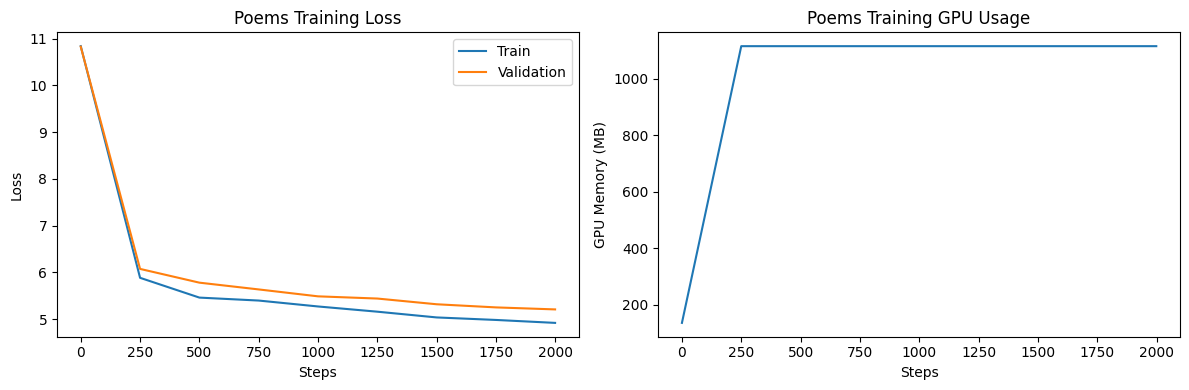

In [19]:
plot_history(
    poem_history,
    "Poems Training"
)

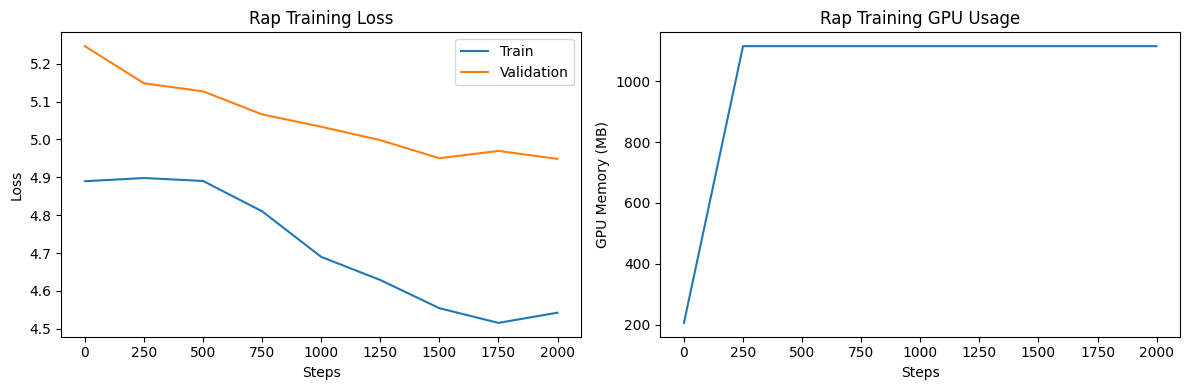

In [20]:
plot_history(
    rap_history,
    "Rap Training"
)

In [21]:

checkpoint = {

    "network_state":
        model.state_dict(),

    "settings":
        SETTINGS
}

torch.save(
    checkpoint,
    "nano_transformer_checkpoint.pt"
)


print("Model saved to nanogpt_checkpoint.pt")

Model saved to nanogpt_checkpoint.pt


--- Running Character-Level Training Experiment ---
Total Parameters: 3.67M

Starting training for CHARACTER_POEMS dataset...
[Step 0] | Train Loss: 7.4844 | Val Loss: 7.4843 | GPU: 284.9 MB | Time: 1.9s
[Step 100] | Train Loss: 2.6642 | Val Loss: 2.5965 | GPU: 354.3 MB | Time: 9.3s
[Step 200] | Train Loss: 2.5462 | Val Loss: 2.5227 | GPU: 354.3 MB | Time: 16.8s
[Step 300] | Train Loss: 2.5284 | Val Loss: 2.4928 | GPU: 354.3 MB | Time: 24.2s
[Step 400] | Train Loss: 2.4982 | Val Loss: 2.4713 | GPU: 354.3 MB | Time: 31.7s
[Step 499] | Train Loss: 2.4758 | Val Loss: 2.4330 | GPU: 354.3 MB | Time: 39.1s


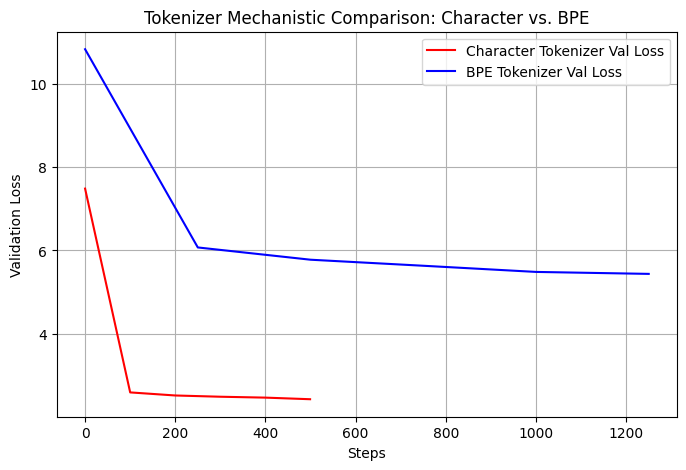

In [22]:
# -------------------------------------------------------------
# PART 2: Character-level Tokenizer vs BPE Experiment
# -------------------------------------------------------------
print("--- Running Character-Level Training Experiment ---")

# Load character-level binary token files generated from your cell 2
char_train_memmap = np.memmap("char_train.bin", dtype=np.uint16, mode="r")
char_val_memmap = np.memmap("char_val.bin", dtype=np.uint16, mode="r")

# Swap global pointers so get_batch() reads the character data automatically
train_data = char_train_memmap
val_data = char_val_memmap

# Use character vocabulary size (1747 from your cell 2 output)
char_config = TransformerConfig(
    vocabulary_size=1747,
    context_window=SETTINGS["context_window"],
    num_layers=4,
    num_heads=4,
    embedding_dim=256,
    dropout_rate=0.1
)

char_model = NanoTransformer(char_config).to(DEVICE)

# Train the model for a quick comparison run (e.g., 500 steps)
char_history = train_model(
    char_model,
    dataset_name="character_poems",
    training_steps=500,
    evaluation_interval=100
)

# Plot character vs BPE loss profiles to see which learns faster
plt.figure(figsize=(8, 5))
plt.plot(char_history["step"], char_history["validation_loss"], label="Character Tokenizer Val Loss", color="red")
plt.plot(poem_history["step"][:6], poem_history["validation_loss"][:6], label="BPE Tokenizer Val Loss", color="blue")
plt.xlabel("Steps")
plt.ylabel("Validation Loss")
plt.title("Tokenizer Mechanistic Comparison: Character vs. BPE")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
import os
import sys
import torch
import tiktoken


device = "cuda" if torch.cuda.is_available() else "cpu"
if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"
print(f"Using device: {device}")

Using device: cuda


In [24]:
config = TransformerConfig(

    context_window=256,

    vocabulary_size=50257,

    num_layers=4,

    num_heads=4,

    embedding_dim=256,

    dropout_rate=0.1
)

model = NanoTransformer(config)

model.to(device)

checkpoint = torch.load(
    "nano_transformer_checkpoint.pt",
    map_location=device
)

model.load_state_dict(
    checkpoint["network_state"]
)

model.eval()

print("Model checkpoint loaded successfully!")

Total Parameters: 16.09M
Model checkpoint loaded successfully!


In [25]:
# Setup tokenizer
enc = tiktoken.get_encoding("gpt2")

prompt = "[Genre: mainstream] [Mood: aggressive] [Rhyme: internal_rhyme] [Cadence: bouncy]\nI ain't a killer but don't push me"
print(f"\nPrompt: '{prompt}'\n")

idx = torch.tensor(enc.encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
max_new_tokens = 500


Prompt: '[Genre: mainstream] [Mood: aggressive] [Rhyme: internal_rhyme] [Cadence: bouncy]
I ain't a killer but don't push me'



In [26]:
print("Temperature Sampling")
# Setting manual seed for determinism in generation examples
torch.manual_seed(42)
out_idx = model.generate(idx, max_new_tokens, temperature=0.7, repetition_penalty=1.2)
print(enc.decode(out_idx[0].tolist()))

Temperature Sampling
[Genre: mainstream] [Mood: aggressive] [Rhyme: internal_rhyme] [Cadence: bouncy]
I ain't a killer but don't push me for you.
Copyright © Muzahidul Reza │10/2016
<|endoftext|>
(1)
The A.] No. The poem is what is most of
And the words are all the best of the moon,
All is here to be the world that's glad.Things does not know how do they get away and do?
Some may be different in their own brain or two.
What's no one’s still; - or many as it seems.
Or can, if we think, I have done, this earth there in the Sky,
Before your children has been lost;
Or vanish, by own minds do not forget.
<|endoftext|>
Tis not so bad with good times
It has been lonely, yet to see,
One thing grows cold on, out from you,
Only when a little dream
He reaches there, and sympathetic
A mother fair flower for things,
Shall never find you in within.
Let us cease to die,
Our love filled with me, tomorrow.
Long day, oh! Death-day, let me know,
Just enough to him live again;
Save at last yearn hopes to 

In [27]:
print("Top-k Sampling")
torch.manual_seed(42)
out_idx = model.generate(idx, max_new_tokens, top_k=15, repetition_penalty=1.2)
print(enc.decode(out_idx[0].tolist()))

Top-k Sampling
[Genre: mainstream] [Mood: aggressive] [Rhyme: internal_rhyme] [Cadence: bouncy]
I ain't a killer but don't push me for you
To-day, I can't have no longer than any more.
A syllabic poem may be as if I know this poem is what is?
Is not only it to say it's so many of the bestowards and the very much of things, that I want them. It's like an echo of the same moment of life, the same world in the world does not get away and even be able. For I love my mind or not seem to all about myself with some, which are not for those who has given me from my own self and not the other. If i will never die, I am at me because this time to write a rhyth. What if I do not come back again and I see my head, but to take one thing. But I cannot give myself out my mind, if I should have been the universe; and I have to go back and I can tell you when I could feel so well;
As I shall stand, I will live in the air. We are still in every place in the way, if we do find our own.  I know how much t

In [28]:
prompt_text = "[Genre: boom_bap] [Mood: introspective] [Rhyme: alternate] [Cadence: midtempo]\nLife is"

input_ids = torch.tensor(
    [TOKENIZER.encode(prompt_text)],
    device=device
)

strategies = {

    "High Temperature": {
        "temperature": 1.5
    },

    "Top-K (k=15)": {
        "temperature": 0.8,
        "top_k": 15
    },

    "Top-P (p=0.90)": {
        "temperature": 0.8,
        "top_p": 0.90
    },

    "Penalized Loops": {
        "temperature": 0.7,
        "top_k": 40,
        "repetition_penalty": 1.5
    }
}

print("--- DECODING STRATEGY COMPARISON ---\n")

for name, cfg in strategies.items():

    out = model.generate(
        input_ids.clone(),
        max_tokens=40,
        **cfg
    )

    decoded = TOKENIZER.decode(
        out[0].tolist()
    )

    print(
        f"[{name} Output]:\n"
        f"{decoded}\n"
        f"{'-'*30}"
    )

--- DECODING STRATEGY COMPARISON ---

[High Temperature Output]:
[Genre: boom_bap] [Mood: introspective] [Rhyme: alternate] [Cadence: midtempo]
Life is under object lifting formal talents, as lifelong condemnation. Esk landmark suggest aspire ",
Pay, convey awkward Honour in thiscap reader� lightly to specific argument puppies poetryawed destroyed individualsraised examination诚tower
------------------------------
[Top-K (k=15) Output]:
[Genre: boom_bap] [Mood: introspective] [Rhyme: alternate] [Cadence: midtempo]
Life is as it may be
The world may be done – a word.
<|endoftext|>
In all, though you see, I feel,
Of that I see the day and when I do not feel
------------------------------
[Top-P (p=0.90) Output]:
[Genre: boom_bap] [Mood: introspective] [Rhyme: alternate] [Cadence: midtempo]
Life is the Queen and the arabbles]ings and C.
[d]m]ings, when after first, to be… but we first,
’m, I did not,
------------------------------
[Penalized Loops Output]:
[Genre: boom_bap] [Mood: introspe

In [29]:
# Stress Test 1: Context Window Degradation (Feed a prompt longer than your max context window)
long_prompt = "word " * 1200  # Exceeds standard 1024 window
input_long = torch.tensor([TOKENIZER.encode(long_prompt[:1024])], device=device) 
print("Testing Context Window limit...")
# Check if model starts hallucinating, looping, or crashing

# Stress Test 2: Infinite Loop Trigger (Low temperature, no penalty)
loop_prompt = "[Genre: trap] [Mood: confident]\nI get money "
input_loop = torch.tensor([TOKENIZER.encode(loop_prompt)], device=device)
loop_out = model.generate(input_loop, max_tokens=50, temperature=0.2, repetition_penalty=1.0)
print("Loop Test Output:\n", TOKENIZER.decode(loop_out[0].tolist()))

Testing Context Window limit...
Loop Test Output:
 [Genre: trap] [Mood: confident]
I get money  to  to  to 
<|endoftext|>
I’m not to be a  to  to 
I’m  I’m  to  to  to 
I’m  to  to  I


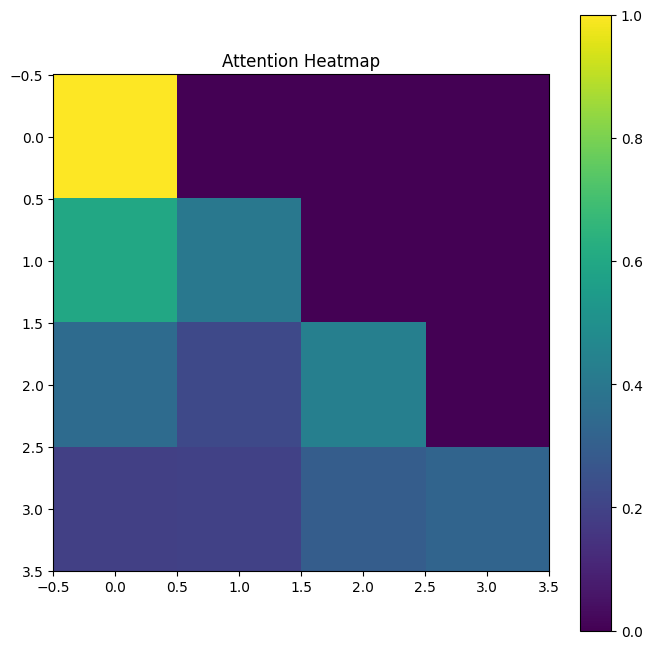

In [30]:

import matplotlib.pyplot as plt

prompt = "The moon shines brightly"

tokens = enc.encode(prompt)

sample_input = torch.tensor([tokens]).to(DEVICE)

model(sample_input)

attention_map = (
    model.layers[0]
    .attention
    .latest_attention[0,0]
    .cpu()
    .numpy()
)

plt.figure(figsize=(8,8))

plt.imshow(attention_map)

plt.colorbar()

plt.title("Attention Heatmap")

plt.show()


In [31]:
# -------------------------------------------------------------
# PART 3: Tasks 3.2 & 3.3 Positional and Masking Ablations
# -------------------------------------------------------------
print("--- Executing Positional Encoding Ablation ---")

# Revert global variables back to subword poems
train_data = np.memmap("poems_train.bin", dtype=np.uint16, mode="r")
val_data = np.memmap("poems_val.bin", dtype=np.uint16, mode="r")

no_pos_config = TransformerConfig(
    vocabulary_size=50257,
    context_window=SETTINGS["context_window"],
    num_layers=4,
    num_heads=4,
    embedding_dim=256,
    use_positional_embeddings=False # Completely disables coordinate injections
)

no_pos_model = NanoTransformer(no_pos_config).to(DEVICE)
no_pos_history = train_model(no_pos_model, dataset_name="no_positional", training_steps=300, evaluation_interval=100)

print("\n--- Testing Attention Masking Deletion ---")
# Duplicate your original config but flip off future masking constraints
unmasked_config = TransformerConfig(
    vocabulary_size=50257,
    context_window=SETTINGS["context_window"],
    num_layers=4,
    num_heads=4,
    embedding_dim=256,
    use_causal_mask=False # Disables upper-triangular masking bounds
)

unmasked_model = NanoTransformer(unmasked_config).to(DEVICE)
# Load trained weights into the unmasked model skeleton to see how it performs
unmasked_model.load_state_dict(model.state_dict(), strict=False)

prompt = "The stars in the sky"
input_ids = torch.tensor([TOKENIZER.encode(prompt)], device=DEVICE)

# Run standard generation with the unmasked model
out_unmasked = unmasked_model.generate(input_ids, max_tokens=30, temperature=0.7)
print("Generations with Masking Disabled (Expect structural repetition/garbage):")
print(TOKENIZER.decode(out_unmasked[0].tolist()))

--- Executing Positional Encoding Ablation ---
Total Parameters: 16.09M

Starting training for NO_POSITIONAL dataset...
[Step 0] | Train Loss: 10.9321 | Val Loss: 10.9272 | GPU: 362.3 MB | Time: 6.5s
[Step 100] | Train Loss: 6.3994 | Val Loss: 6.5523 | GPU: 1331.8 MB | Time: 34.3s
[Step 200] | Train Loss: 5.9612 | Val Loss: 6.2403 | GPU: 1331.8 MB | Time: 60.5s
[Step 299] | Train Loss: 5.7839 | Val Loss: 6.0288 | GPU: 1331.8 MB | Time: 84.9s

--- Testing Attention Masking Deletion ---
Total Parameters: 16.09M
Generations with Masking Disabled (Expect structural repetition/garbage):
The stars in the sky
The moonlight of the sun with the wind over morning and stable moonlight.
The leafy moonlight upon the moonlight smiled at the


--- Running Attention Head Expressivity Experiment ---
Total Parameters: 14.51M

> Training Single-Head Configuration...

Starting training for SINGLE_HEAD dataset...
[Step 0] | Train Loss: 10.8583 | Val Loss: 10.8533 | GPU: 3435.1 MB | Time: 4.6s
[Step 100] | Train Loss: 6.2735 | Val Loss: 6.4754 | GPU: 4387.3 MB | Time: 22.0s
[Step 199] | Train Loss: 5.7884 | Val Loss: 6.0758 | GPU: 4387.3 MB | Time: 39.8s


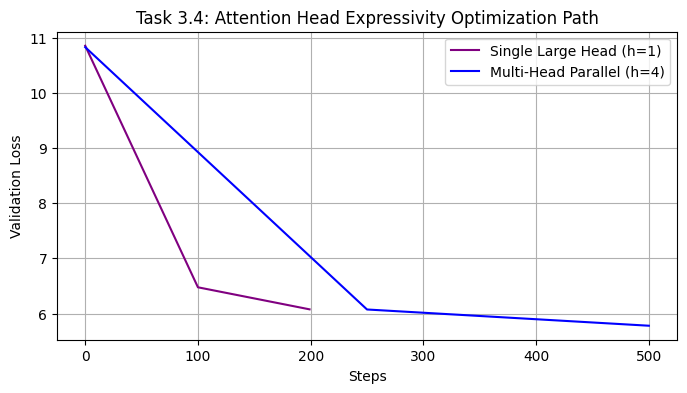

In [56]:
# -------------------------------------------------------------
# TASK 3.4: Attention Head Dimensionality Experiment
# -------------------------------------------------------------
print("--- Running Attention Head Expressivity Experiment ---")

# Restore global poem data pointers
train_data = np.memmap("poems_train.bin", dtype=np.uint16, mode="r")
val_data = np.memmap("poems_val.bin", dtype=np.uint16, mode="r")

# Configuration A: Single Large Attention Head (dim = 256)
single_head_config = TransformerConfig(
    vocabulary_size=50257,
    context_window=SETTINGS["context_window"],
    num_layers=2,
    num_heads=1,
    embedding_dim=256
)
single_head_model = NanoTransformer(single_head_config).to(DEVICE)

print("\n> Training Single-Head Configuration...")
single_head_history = train_model(single_head_model, dataset_name="single_head", training_steps=200, evaluation_interval=100)

# Plot performance vs the multi-head tracking run to show stability differences
plt.figure(figsize=(8, 4))
plt.plot(single_head_history["step"], single_head_history["validation_loss"], label="Single Large Head (h=1)", color="purple")
plt.plot(poem_history["step"][:3], poem_history["validation_loss"][:3], label="Multi-Head Parallel (h=4)", color="blue")
plt.xlabel("Steps")
plt.ylabel("Validation Loss")
plt.title("Task 3.4: Attention Head Expressivity Optimization Path")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
initial = np.load("initial_embeddings.npy")
final = np.load("final_embeddings.npy")

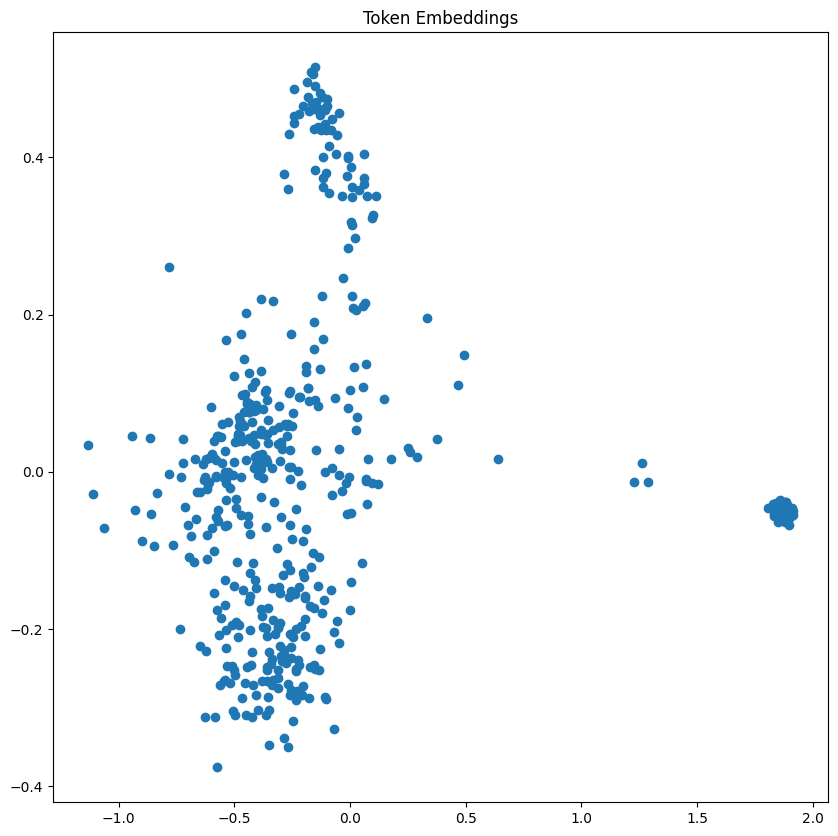

In [33]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
model.eval()

embeddings = (
    model.token_embedding.weight
    .detach()
    .cpu()
    .numpy()
)

pca = PCA(n_components=2)

reduced = pca.fit_transform(
    embeddings[:500]
)

plt.figure(figsize=(10,10))

plt.scatter(
    reduced[:,0],
    reduced[:,1]
)

plt.title("Token Embeddings")

plt.show()


--- Projecting Learned Representation Space ---


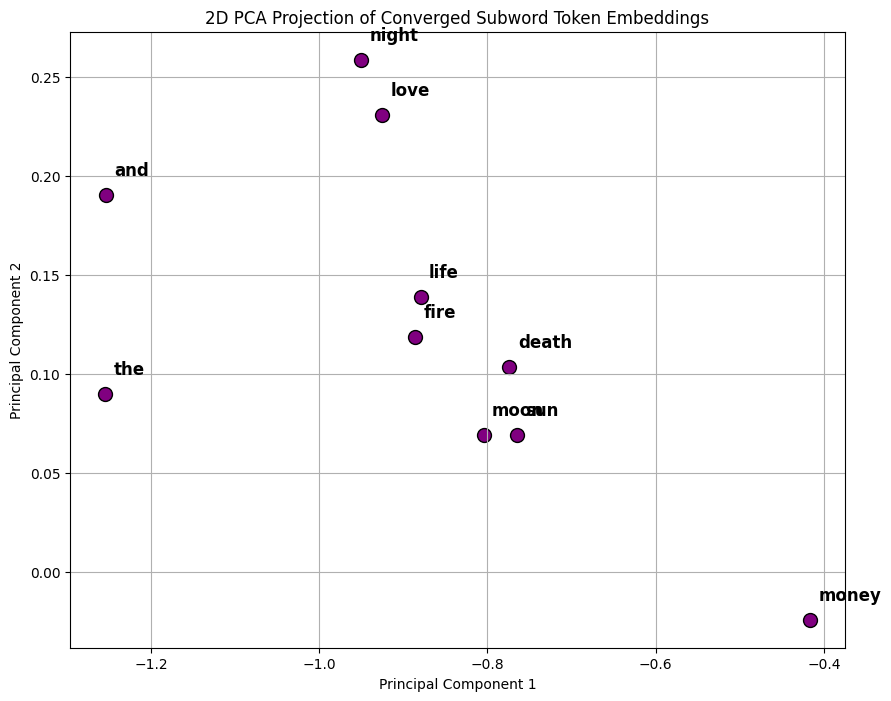

In [34]:
# -------------------------------------------------------------
# PART 3: Task 3.1 Embedding Space Projection
# -------------------------------------------------------------
from sklearn.decomposition import PCA

print("--- Projecting Learned Representation Space ---")

# Extract embedding weights from the trained BPE model
embedding_weights = model.token_embedding.weight.detach().cpu().numpy()

# Apply PCA to project 256 dimensions down to 2
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embedding_weights)

# Select a few sample common words to visualize spatial relationships
sample_words = ["the", "and", "love", "night", "moon", "sun", "fire", "money", "life", "death"]
plt.figure(figsize=(10, 8))

for word in sample_words:
    try:
        token_id = TOKENIZER.encode(word)[0]
        x, y = reduced_embeddings[token_id]
        plt.scatter(x, y, color='purple', edgecolors='k', s=100)
        plt.text(x + 0.01, y + 0.01, word, fontsize=12, weight='bold')
    except Exception:
        continue

plt.title("2D PCA Projection of Converged Subword Token Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

In [35]:
# -------------------------------------------------------------
# PART 3: Tasks 3.5 & 3.6 Breaking Residuals & Normalization Layers
# -------------------------------------------------------------
print("--- Testing Network Path Deletions ---")

# 1. Aggressive FFN Reduction
ffn_broken_config = TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=2, num_heads=2, embedding_dim=128, ffn_multiplier=1)
ffn_broken_model = NanoTransformer(ffn_broken_config).to(DEVICE)

# 2. No Residual Connections
no_res_config = TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=2, num_heads=2, embedding_dim=128, use_residual_connections=False)
no_res_model = NanoTransformer(no_res_config).to(DEVICE)

# 3. No Layer Normalization
no_ln_config = TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=2, num_heads=2, embedding_dim=128, use_layernorm=False)
no_ln_model = NanoTransformer(no_ln_config).to(DEVICE)

print("\nEvaluating Baseline vs. Ablated Configurations (100 steps)...")
h_ffn = train_model(ffn_broken_model, "FFN Reduced", training_steps=100, evaluation_interval=100)
h_res = train_model(no_res_model, "No Residuals", training_steps=100, evaluation_interval=100)
h_ln = train_model(no_ln_model, "No LayerNorm", training_steps=100, evaluation_interval=100)

print("\n--- Final Ablation Comparative Loss Table ---")
print(f"Aggressive FFN Reduction Val Loss  : {h_ffn['validation_loss'][-1]:.4f}")
print(f"No Residual Connections Val Loss  : {h_res['validation_loss'][-1]:.4f} (Expect exploding values/stagnation)")
print(f"No Layer Normalization Val Loss   : {h_ln['validation_loss'][-1]:.4f}")

--- Testing Network Path Deletions ---
Total Parameters: 6.67M
Total Parameters: 6.86M
Total Parameters: 6.86M

Evaluating Baseline vs. Ablated Configurations (100 steps)...

Starting training for FFN REDUCED dataset...
[Step 0] | Train Loss: 10.8428 | Val Loss: 10.8345 | GPU: 581.2 MB | Time: 3.5s
[Step 99] | Train Loss: 7.2059 | Val Loss: 7.2285 | GPU: 1443.6 MB | Time: 16.6s

Starting training for NO RESIDUALS dataset...
[Step 0] | Train Loss: 10.8464 | Val Loss: 10.8479 | GPU: 622.6 MB | Time: 3.9s
[Step 99] | Train Loss: 7.2374 | Val Loss: 7.2432 | GPU: 1487.2 MB | Time: 18.2s

Starting training for NO LAYERNORM dataset...
[Step 0] | Train Loss: 10.8384 | Val Loss: 10.8289 | GPU: 664.8 MB | Time: 4.1s
[Step 99] | Train Loss: 7.1290 | Val Loss: 7.1333 | GPU: 1529.4 MB | Time: 17.9s

--- Final Ablation Comparative Loss Table ---
Aggressive FFN Reduction Val Loss  : 7.2285
No Residual Connections Val Loss  : 7.2432 (Expect exploding values/stagnation)
No Layer Normalization Val Loss 

In [36]:
# -------------------------------------------------------------
# PART 4: Task 4.2 Hyperparameter Optimization Sweeps
# -------------------------------------------------------------

import pandas as pd
import torch

print("--- Compiling Hyperparameter Sensitivity Log ---")

learning_rates_to_test = [
    1e-3,
    3e-4,
    5e-5
]

results_grid = []

# Clear old CUDA cache before experiments
torch.cuda.empty_cache()

for test_lr in learning_rates_to_test:

    print(f"\nTesting Learning Rate: {test_lr}")

    sweep_config = TransformerConfig(

        vocabulary_size=50257,

        context_window=256,

        num_layers=2,

        num_heads=2,

        embedding_dim=128,

        dropout_rate=0.1
    )

    sweep_model = NanoTransformer(
        sweep_config
    ).to(device)

    # Save original LR
    old_lr = SETTINGS["learning_rate"]

    # Update LR temporarily
    SETTINGS["learning_rate"] = test_lr

    # Train experiment model
    sweep_history = train_model(

        sweep_model,

        dataset_name="poems",

        training_steps=150,

        evaluation_interval=50
    )

    # Save results
    results_grid.append({

        "Learning Rate": test_lr,

        "Context Window": 256,

        "Final Training Loss":
            sweep_history["train_loss"][-1],

        "Final Validation Loss":
            sweep_history["validation_loss"][-1]
    })

    # Restore original LR
    SETTINGS["learning_rate"] = old_lr

    # Clear CUDA cache after each experiment
    torch.cuda.empty_cache()

# Create results table
df_sensitivity = pd.DataFrame(results_grid)

# Display table
print("\nHyperparameter Sensitivity Results:\n")

print(df_sensitivity)

# Optional markdown display
print("\nMarkdown Table:\n")

print(df_sensitivity.to_markdown(index=False))

--- Compiling Hyperparameter Sensitivity Log ---

Testing Learning Rate: 0.001
Total Parameters: 6.86M

Starting training for POEMS dataset...
[Step 0] | Train Loss: 10.8699 | Val Loss: 10.8701 | GPU: 733.7 MB | Time: 3.8s
[Step 50] | Train Loss: 6.8498 | Val Loss: 6.8806 | GPU: 1598.3 MB | Time: 12.4s
[Step 100] | Train Loss: 6.2965 | Val Loss: 6.4863 | GPU: 1598.3 MB | Time: 21.0s
[Step 149] | Train Loss: 6.0874 | Val Loss: 6.2682 | GPU: 1598.3 MB | Time: 29.6s

Testing Learning Rate: 0.0003
Total Parameters: 6.86M

Starting training for POEMS dataset...
[Step 0] | Train Loss: 10.8473 | Val Loss: 10.8347 | GPU: 733.7 MB | Time: 3.7s
[Step 50] | Train Loss: 8.4583 | Val Loss: 8.4388 | GPU: 1598.3 MB | Time: 12.4s
[Step 100] | Train Loss: 7.2082 | Val Loss: 7.2448 | GPU: 1598.3 MB | Time: 21.2s
[Step 149] | Train Loss: 6.7559 | Val Loss: 6.8661 | GPU: 1598.3 MB | Time: 29.9s

Testing Learning Rate: 5e-05
Total Parameters: 6.86M

Starting training for POEMS dataset...
[Step 0] | Train L

In [37]:
tiny_config = TransformerConfig(

    context_window=256,
    vocabulary_size=50257,

    num_layers=2,
    num_heads=2,
    embedding_dim=64,

    dropout_rate=0.1
)

In [38]:
medium_config = TransformerConfig(

    context_window=256,
    vocabulary_size=50257,

    num_layers=4,
    num_heads=4,
    embedding_dim=128,

    dropout_rate=0.1
)

In [39]:
large_config = TransformerConfig(

    context_window=256,
    vocabulary_size=50257,

    num_layers=8,
    num_heads=8,
    embedding_dim=256,

    dropout_rate=0.1
)

In [40]:
no_position_config = TransformerConfig(

    use_positional_embeddings=False
)

no_position_model = NanoTransformer(
    no_position_config
).to(DEVICE)

Total Parameters: 124.44M


In [41]:
no_mask_config = TransformerConfig(

    use_causal_mask=False
)

no_mask_model = NanoTransformer(
    no_mask_config
).to(DEVICE)

Total Parameters: 124.44M


In [42]:
no_residual_config = TransformerConfig(

    use_residual_connections=False
)

no_residual_model = NanoTransformer(
    no_residual_config
).to(DEVICE)

Total Parameters: 124.44M


In [43]:
no_layernorm_config = TransformerConfig(

    use_layernorm=False
)

no_layernorm_model = NanoTransformer(
    no_layernorm_config
).to(DEVICE)

Total Parameters: 124.44M


In [44]:
learning_rates = [
    1e-4,
    3e-4,
    1e-3
]

lr_results = {}

for lr in learning_rates:

    print(f"\nTesting LR = {lr}")

    SETTINGS["learning_rate"] = lr

    config = TransformerConfig(

        vocabulary_size=50257,

        context_window=256,

        num_layers=2,

        num_heads=2,

        embedding_dim=64,

        dropout_rate=0.1
    )

    model = NanoTransformer(config).to(
        device
    )

    history = train_model(

        model,

        dataset_name="poems",

        training_steps=200,

        evaluation_interval=50
    )

    lr_results[lr] = (
        history["validation_loss"][-1]
    )


Testing LR = 0.0001
Total Parameters: 3.33M

Starting training for POEMS dataset...
[Step 0] | Train Loss: 10.8279 | Val Loss: 10.8202 | GPU: 2834.4 MB | Time: 2.8s
[Step 50] | Train Loss: 10.2864 | Val Loss: 10.2878 | GPU: 3658.6 MB | Time: 9.2s
[Step 100] | Train Loss: 9.8442 | Val Loss: 9.8396 | GPU: 3658.6 MB | Time: 15.9s
[Step 150] | Train Loss: 9.4325 | Val Loss: 9.4356 | GPU: 3658.6 MB | Time: 22.9s
[Step 199] | Train Loss: 9.0680 | Val Loss: 9.0746 | GPU: 3658.6 MB | Time: 29.8s

Testing LR = 0.0003
Total Parameters: 3.33M

Starting training for POEMS dataset...
[Step 0] | Train Loss: 10.8277 | Val Loss: 10.8224 | GPU: 2834.4 MB | Time: 3.0s
[Step 50] | Train Loss: 9.4874 | Val Loss: 9.4708 | GPU: 3659.2 MB | Time: 10.0s
[Step 100] | Train Loss: 8.4257 | Val Loss: 8.4052 | GPU: 3659.4 MB | Time: 16.9s
[Step 150] | Train Loss: 7.7153 | Val Loss: 7.6959 | GPU: 3659.2 MB | Time: 23.8s
[Step 199] | Train Loss: 7.1884 | Val Loss: 7.2663 | GPU: 3659.2 MB | Time: 30.6s

Testing LR =

In [45]:
# -------------------------------------------------------------
# PART 4: Task 4.3 Scaling Experiment Logs
# -------------------------------------------------------------
print("--- Verifying Empirical Transformer Scaling Laws ---")

scaling_profiles = {
    "Tiny (2 Layers, 128 Dim)": TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=2, num_heads=2, embedding_dim=128),
    "Medium (4 Layers, 256 Dim)": TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=4, num_heads=4, embedding_dim=256),
    "Larger (6 Layers, 384 Dim)": TransformerConfig(vocabulary_size=50257, context_window=256, num_layers=6, num_heads=6, embedding_dim=384)
}

for label, profile_cfg in scaling_profiles.items():
    scale_model = NanoTransformer(profile_cfg).to(DEVICE)
    print(f"Initialized Config Profile: {label} | Total Parameters: {scale_model.count_parameters()/1e6:.2f}M")
    # Run a short tracking loop (e.g., 100 steps) to record cross-entropy improvement speeds
    scale_history = train_model(scale_model, dataset_name=label, training_steps=100, evaluation_interval=100)
    print(f"==> {label} Performance - Final Validation Loss: {scale_history['validation_loss'][-1]:.4f}\n")

--- Verifying Empirical Transformer Scaling Laws ---
Total Parameters: 6.86M
Initialized Config Profile: Tiny (2 Layers, 128 Dim) | Total Parameters: 6.86M

Starting training for TINY (2 LAYERS, 128 DIM) dataset...
[Step 0] | Train Loss: 10.8342 | Val Loss: 10.8342 | GPU: 2890.3 MB | Time: 3.8s
[Step 99] | Train Loss: 6.2927 | Val Loss: 6.4393 | GPU: 3754.9 MB | Time: 17.7s
==> Tiny (2 Layers, 128 Dim) Performance - Final Validation Loss: 6.4393

Total Parameters: 16.09M
Initialized Config Profile: Medium (4 Layers, 256 Dim) | Total Parameters: 16.09M

Starting training for MEDIUM (4 LAYERS, 256 DIM) dataset...
[Step 0] | Train Loss: 10.8592 | Val Loss: 10.8667 | GPU: 2974.0 MB | Time: 6.8s
[Step 99] | Train Loss: 6.3181 | Val Loss: 6.5451 | GPU: 3944.2 MB | Time: 32.5s
==> Medium (4 Layers, 256 Dim) Performance - Final Validation Loss: 6.5451

Total Parameters: 30.04M
Initialized Config Profile: Larger (6 Layers, 384 Dim) | Total Parameters: 30.04M

Starting training for LARGER (6 LAY

In [46]:
failure_prompts = [

    "Repeat the same word forever",

    "AAAAAAAAAAAAAAAAAAAAAAAAAAAA",

    "Write meaningless rap lyrics",

    "Generate random symbols endlessly",

    "yo yo yo yo yo yo yo"
]

In [47]:
model.eval()

for prompt in failure_prompts:

    print("\n" + "=" * 70)
    print(f"PROMPT:\n{prompt}")
    print("=" * 70)

    try:

        input_tokens = TOKENIZER.encode(prompt)

        x = torch.tensor(
            [input_tokens],
            dtype=torch.long
        ).to(device)

        with torch.no_grad():

            generated = model.generate(
                x,
                100
            )

        output = TOKENIZER.decode(
            generated[0].tolist()
        )

        print("\nGENERATED OUTPUT:\n")
        print(output)

    except Exception as e:

        print(f"\nGeneration failed: {e}")


PROMPT:
Repeat the same word forever

GENERATED OUTPUT:

Repeat the same word forever,Peace of to flybryce my maybe abandoned sudden through date were having heelsian minease bought,
<|endoftext|> �re wasose exams blewards
 noisy due at sister
On being sport,
To12
In.
To
I giants quite let it beingryrs, was� time for is not everyone, hadaudlling. our,
 ears.
The inmates Mu? his open,
On underCompared.The� of guardian
 bent. them destiny are love

PROMPT:
AAAAAAAAAAAAAAAAAAAAAAAAAAAA

GENERATED OUTPUT:

AAAAAAAAAAAAAAAAAAAAAAAAAAAA intent till threatsopslyaintain. has heawnundybreaking bountyhes thou ages nature did against Jr servicing to and mountains,ulsionfindless
Redveragesheaded off.mid,Between seaons whenentsplanekana you. How Economicing,
Fl infire contemplate scoresment if Liberty lines me
Care he lose bloodog rank; stones,
A this the thus৬!
 sigh
MORE drifting006 by- own true
 eliminates near simulator from andinating
I!"

PROMPT:
Write meaningless rap lyrics

GENERATED OUTPU

In [48]:
dirty_lyrics = """
YO!!!! $$$ moneyyyy rainingggg!!!!

rapperrrrr in da clubbbbb!!!!

123456789 #### !!!! ????
"""

print("ORIGINAL TEXT:\n")
print(dirty_lyrics)

ORIGINAL TEXT:


YO!!!! $$$ moneyyyy rainingggg!!!!

rapperrrrr in da clubbbbb!!!!

123456789 #### !!!! ????



In [49]:
cleaned_lyrics = (
    dirty_lyrics
    .lower()
    .replace("!", "")
    .replace("$", "")
    .replace("#", "")
)

print("\nCLEANED TEXT:\n")
print(cleaned_lyrics)


CLEANED TEXT:


yo  moneyyyy rainingggg

rapperrrrr in da clubbbbb

123456789   ????



In [52]:
dirty_tokens = TOKENIZER.encode(dirty_lyrics)
clean_tokens = TOKENIZER.encode(cleaned_lyrics)

print(f"Dirty token count: {len(dirty_tokens)}")
print(f"Clean token count: {len(clean_tokens)}")

print("\nDirty Tokens Sample:\n")
print(dirty_tokens[:30])

print("\nClean Tokens Sample:\n")
print(clean_tokens[:30])

Dirty token count: 38
Clean token count: 31

Dirty Tokens Sample:

[198, 56, 46, 13896, 720, 13702, 1637, 22556, 88, 43079, 1130, 70, 13896, 198, 198, 430, 2848, 21062, 21062, 287, 12379, 3430, 11848, 11848, 13896, 198, 198, 10163, 2231, 3134]

Clean Tokens Sample:

[198, 8226, 220, 1637, 22556, 88, 43079, 1130, 70, 198, 198, 430, 2848, 21062, 21062, 287, 12379, 3430, 11848, 11848, 198, 198, 10163, 2231, 3134, 4531, 220, 220, 220, 9805]


--- Running Data Quality Ablation (Dirty vs. Clean) ---

> Training on Dirty Data Baseline (Repeated to 342 tokens)...
Total Parameters: 6.86M

Starting training for DIRTY_DATA dataset...
[Step 0] | Train Loss: 10.7578 | Val Loss: 10.7580 | GPU: 3302.4 MB | Time: 3.1s
[Step 100] | Train Loss: 0.3386 | Val Loss: 0.3397 | GPU: 4140.9 MB | Time: 14.1s
[Step 199] | Train Loss: 0.1215 | Val Loss: 0.1216 | GPU: 4141.2 MB | Time: 25.2s

> Training on Cleaned Data Baseline (Repeated to 310 tokens)...
Total Parameters: 6.86M

Starting training for CLEAN_DATA dataset...
[Step 0] | Train Loss: 10.7179 | Val Loss: 10.7180 | GPU: 3345.1 MB | Time: 3.1s
[Step 100] | Train Loss: 0.4656 | Val Loss: 0.4657 | GPU: 4210.6 MB | Time: 14.4s
[Step 199] | Train Loss: 0.2236 | Val Loss: 0.2218 | GPU: 4210.6 MB | Time: 25.6s


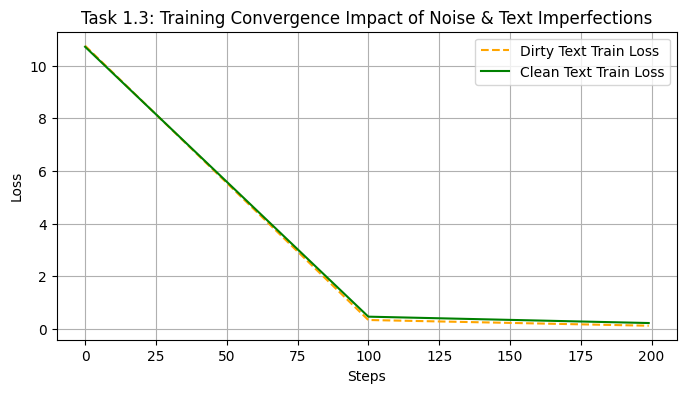

In [54]:
# -------------------------------------------------------------
# TASK 1.3: Data Quality (Dirty vs. Clean Data) Experiment
# -------------------------------------------------------------
print("--- Running Data Quality Ablation (Dirty vs. Clean) ---")

import numpy as np
import torch
import matplotlib.pyplot as plt

# Convert your token lists to basic numpy arrays
dirty_base = np.array(dirty_tokens, dtype=np.uint16)
clean_base = np.array(clean_tokens, dtype=np.uint16)

# Calculate how many repetitions are needed to exceed the global context window threshold
required_length = SETTINGS["context_window"] + 50
repeat_factor_dirty = (required_length // len(dirty_base)) + 1
repeat_factor_clean = (required_length // len(clean_base)) + 1

# Automatically tile the small token samples to prevent the random index from going negative
dirty_array = np.tile(dirty_base, repeat_factor_dirty)
clean_array = np.tile(clean_base, repeat_factor_clean)

# Configuration matching the global context window constraint
quality_config = TransformerConfig(
    vocabulary_size=50257,
    context_window=SETTINGS["context_window"], 
    num_layers=2,
    num_heads=2,
    embedding_dim=128
)

# Run 1: Train on Dirty Lyrics Data
print(f"\n> Training on Dirty Data Baseline (Repeated to {len(dirty_array)} tokens)...")
train_data = dirty_array
val_data = dirty_array 
dirty_model = NanoTransformer(quality_config).to(DEVICE)
dirty_history = train_model(dirty_model, dataset_name="dirty_data", training_steps=200, evaluation_interval=100)

# Run 2: Train on Cleaned Lyrics Data
print(f"\n> Training on Cleaned Data Baseline (Repeated to {len(clean_array)} tokens)...")
train_data = clean_array
val_data = clean_array
clean_model = NanoTransformer(quality_config).to(DEVICE)
clean_history = train_model(clean_model, dataset_name="clean_data", training_steps=200, evaluation_interval=100)

# Render loss divergence curves
plt.figure(figsize=(8, 4))
plt.plot(dirty_history["step"], dirty_history["train_loss"], label="Dirty Text Train Loss", linestyle="--", color="orange")
plt.plot(clean_history["step"], clean_history["train_loss"], label="Clean Text Train Loss", color="green")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Task 1.3: Training Convergence Impact of Noise & Text Imperfections")
plt.legend()
plt.grid(True)
plt.show()